# Drug targets in the cell

Takes a list of drugs (a plate-map CSV, a text list, or names/ChEMBL IDs), finds each drug in **ChEMBL**, pulls its mechanism-of-action targets, looks those proteins up in **UniProt**, and plots where in the cell they act.

## Setup
Requires `requests`, `matplotlib` and `numpy` (`pip install requests matplotlib numpy`). API calls retry automatically on rate limits and server errors.

In [1]:
import csv
import math
import os
import pathlib
import sys
import textwrap
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from functools import lru_cache

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Arc, Circle, Ellipse, FancyBboxPatch, Rectangle
from matplotlib.transforms import Affine2D
from notebook_init_utils.notebook_init_utils import init_notebook

root_dir, in_notebook = init_notebook()

CHEMBL = "https://www.ebi.ac.uk/chembl/api/data"
UNIPROT = "https://rest.uniprot.org/uniprotkb"
S = requests.Session()
S.headers["Accept"] = "application/json"
S.mount(
    "https://",
    requests.adapters.HTTPAdapter(
        max_retries=requests.adapters.Retry(
            total=4, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504]
        )
    ),
)


def get(url, **params):
    r = S.get(url, params=params, timeout=90)
    r.raise_for_status()
    return r.json()

In [2]:
# Input: a plate-map CSV (drug names in COLUMN), a text file (one drug per line),
# (a string or pathlib.Path), or a Python list of names / ChEMBL IDs, e.g. ["selumetinib", "imatinib", "CHEMBL25"]
INPUT = pathlib.Path(f"{root_dir}/config/platemaps/platemap2.csv")
COLUMN = "Treatment"  # column holding drug names when INPUT is a plate-map CSV
ALL_EVIDENCE = False  # False = only experimentally supported GO terms (recommended)
WORKERS = 6  # parallel API requests

# output file paths
cell_structures_targets_image_out_file_path = pathlib.Path(
    f"{root_dir}/figures/drugs_figure/figures/cell_structures_targets.png"
)
cell_protein_targets_results_out_file_path = pathlib.Path(
    f"{root_dir}/figures/drugs_figure/results/cell_protein_targets_results.csv"
)
cell_protein_targets_image_out_file_path = pathlib.Path(
    f"{root_dir}/figures/drugs_figure/figures/cell_protein_targets.png"
)
cell_structures_targets_image_out_file_path.parent.mkdir(parents=True, exist_ok=True)
cell_protein_targets_results_out_file_path.parent.mkdir(parents=True, exist_ok=True)
cell_protein_targets_image_out_file_path.parent.mkdir(parents=True, exist_ok=True)

## Drug name → ChEMBL ID
Tries an exact preferred name, then an exact synonym, then free-text search. Prefers the parent compound (not a salt) and the most advanced clinical phase. ChEMBL IDs are accepted directly.

In [3]:
def resolve_drug(query):
    """Return (chembl_id, pref_name) for a drug name/synonym/ChEMBL ID, or (None, None)."""
    q = query.strip()
    if q.upper().startswith("CHEMBL"):
        m = get(f"{CHEMBL}/molecule/{q.upper()}.json")
        return m["molecule_chembl_id"], m.get("pref_name") or q
    # 1) exact preferred name, 2) exact synonym, 3) free-text search
    for params in (
        {"pref_name__iexact": q},
        {"molecule_synonyms__molecule_synonym__iexact": q},
    ):
        hits = get(f"{CHEMBL}/molecule.json", limit=20, **params)["molecules"]
        if hits:
            break
    else:
        hits = get(f"{CHEMBL}/molecule/search.json", q=q, limit=10)["molecules"]
    if not hits:
        return None, None

    # prefer the parent compound and the most advanced clinical phase
    def score(m):
        is_parent = (m.get("molecule_hierarchy") or {}).get("parent_chembl_id") == m[
            "molecule_chembl_id"
        ]
        return (is_parent, float(m.get("max_phase") or 0))

    best = max(hits, key=score)
    parent = (best.get("molecule_hierarchy") or {}).get("parent_chembl_id") or best[
        "molecule_chembl_id"
    ]
    return parent, best.get("pref_name") or q

## ChEMBL mechanisms and targets
Mechanisms are often filed under a salt form, so they are queried by parent **and** by ID. A ChEMBL target can be a single protein, a complex or a family; each component's UniProt accession is returned.

In [4]:
def get_mechanisms(chembl_id):
    """Mechanisms are often stored on a salt form, so query by parent AND by id."""
    seen, mechs = set(), []
    for key in ("parent_molecule_chembl_id", "molecule_chembl_id"):
        for m in get(f"{CHEMBL}/mechanism.json", **{key: chembl_id, "limit": 1000})[
            "mechanisms"
        ]:
            if m["mec_id"] not in seen and m.get("target_chembl_id"):
                seen.add(m["mec_id"])
                mechs.append(m)
    return mechs


@lru_cache(maxsize=None)
def target_accessions(target_chembl_id):
    """A ChEMBL target can be a single protein, a complex, or a family."""
    t = get(f"{CHEMBL}/target/{target_chembl_id}.json")
    accs = tuple(
        c["accession"] for c in t.get("target_components", []) if c.get("accession")
    )
    return t.get("pref_name"), t.get("target_type"), t.get("organism"), accs

## UniProt entries and GO Cellular Component terms

In [5]:
@lru_cache(maxsize=None)
def uniprot_entry(acc):
    return get(f"{UNIPROT}/{acc}.json")


@lru_cache(maxsize=None)
def uniprot_info(acc):
    d = uniprot_entry(acc)
    gene = (d.get("genes") or [{}])[0].get("geneName", {}).get("value", acc)
    go_cc = []
    for x in d.get("uniProtKBCrossReferences", []):
        if x["database"] == "GO":
            props = {p["key"]: p["value"] for p in x.get("properties", [])}
            term = props.get("GoTerm", "")
            if term.startswith("C:"):  # C = cellular component
                go_cc.append((x["id"], term[2:], props.get("GoEvidenceType", "")))
    return gene, tuple(go_cc)

## GO term → cell compartment (GO plot)
Keyword matching on GO term names; first match wins. `EXPERIMENTAL` lists the GO evidence codes kept when `ALL_EVIDENCE = False`.

In [6]:
# Keyword matching on GO CC term names. Order matters (first match wins).
COMPARTMENTS = [
    ("Extracellular", ["extracellular", "secreted"]),
    (
        "Plasma membrane",
        [
            "plasma membrane",
            "cell surface",
            "focal adhesion",
            "cell junction",
            "adherens",
            "ruffle",
            "lamellipodium",
            "filopodium",
            "caveola",
            "synap",
            "receptor complex",
            "axon",
            "dendrite",
        ],
    ),
    ("Nucleus", ["nucle", "chromatin", "chromosome", "spliceosom"]),
    ("Mitochondrion", ["mitochondri"]),
    ("Endoplasmic reticulum", ["endoplasmic reticulum"]),
    ("Golgi", ["golgi"]),
    ("Endosome / Lysosome", ["endosom", "lysosom", "vacuol", "vesicle"]),
    (
        "Cytoskeleton",
        ["cytoskelet", "microtubule", "actin", "centrosome", "spindle", "cilium"],
    ),
    ("Cytoplasm", ["cytoplasm", "cytosol", "perinuclear", "intracellular"]),
]
COMP_NAMES = [c for c, _ in COMPARTMENTS]

# GO evidence codes from experiments vs. computational inference (IEA, ISS, ...)
EXPERIMENTAL = {"EXP", "IDA", "IPI", "IMP", "IGI", "IEP", "HDA", "HTP", "HMP"}


def compartment_of(term_name):
    low = term_name.lower()
    for comp, keys in COMPARTMENTS:
        if any(k in low for k in keys):
            return comp
    return None

## Primary location and process (protein map)
Each protein gets **one** location from UniProt's curated subcellular location: a transmembrane location wins; otherwise the head term of the first listed location; otherwise the most common GO compartment.

Process (card colour) comes from gene-prefix rules, then UniProt keywords.

**✏️ Edit here:** `LOCATION_OVERRIDES`, `PROCESS_GENE_RULES`, `PROCESS_KEYWORD_RULES`.

In [7]:
# UniProt's curated "Subcellular location" lists locations with the main one first.
UNIPROT_LOC_RULES = [
    ("Extracellular", ["secreted", "extracellular"]),
    (
        "Plasma membrane",
        [
            "cell membrane",
            "plasma membrane",
            "cell surface",
            "cell projection",
            "cell junction",
            "synapse",
            "apical",
            "basolateral",
            "sarcolemma",
        ],
    ),
    ("Nucleus", ["nucle", "chromosome"]),
    ("Mitochondrion", ["mitochond"]),
    (
        "Endoplasmic reticulum",
        ["endoplasmic reticulum", "sarcoplasmic reticulum", "microsome"],
    ),
    ("Golgi", ["golgi"]),
    ("Endosome / Lysosome", ["lysosom", "endosom", "vacuol", "vesicle", "melanosome"]),
    ("Cytoskeleton", ["cytoskeleton", "centrosome", "microtubule"]),
    ("Cytoplasm", ["cytoplasm", "cytosol"]),
]
# Gene-prefix overrides where the head-term rule misleads (edit freely)
LOCATION_OVERRIDES = {"TUBA": "Cytoskeleton", "TUBB": "Cytoskeleton"}


def _uniprot_comp(text):
    low = text.lower()
    for comp, keys in UNIPROT_LOC_RULES:
        if any(k in low for k in keys):
            return comp
    return None


def primary_location(acc, gene, go_terms):
    """(compartment, UniProt text, is_transmembrane). Rules, in order:
    1) a transmembrane location (single/multi-pass, GPI) wins - that's where it sits;
    2) otherwise the head term of the first listed location ("Cytoplasm, cytosol" -> Cytoplasm);
    3) otherwise the most common compartment among the GO terms."""
    for pre, comp in LOCATION_OVERRIDES.items():
        if gene.startswith(pre):
            return comp, "override", False
    locs = []
    for c in uniprot_entry(acc).get("comments", []):
        if c.get("commentType") == "SUBCELLULAR LOCATION":
            for l in c.get("subcellularLocations", []):
                locs.append(
                    (l["location"]["value"], (l.get("topology") or {}).get("value", ""))
                )
    for val, topo in locs:
        if "pass" in topo.lower() or "gpi" in topo.lower():
            # a bare "Membrane" on a transmembrane protein almost always means the cell membrane
            comp = _uniprot_comp(val) or (
                "Plasma membrane" if val.lower() == "membrane" else None
            )
            if comp:
                return comp, f"{val} [{topo}]", True
    for val, topo in locs:
        head = val.split(",")[0].strip()
        if head.lower() == "membrane":  # too generic, try the next one
            continue
        comp = _uniprot_comp(head)
        if comp:
            return comp, val + (f" [{topo}]" if topo else ""), False
    if go_terms:
        counts = defaultdict(int)
        for comp, *_ in go_terms:
            counts[comp] += 1
        return max(counts, key=counts.get), "GO (most frequent)", False
    return "Cytoplasm", "unknown", False


# Process/pathway assignment: gene-prefix rules first, then UniProt keywords. Edit freely.
PROCESS_GENE_RULES = [
    ("MAPK cascade", ["MAP2K", "MAPK", "BRAF", "RAF1", "ARAF", "KRAS", "NRAS", "HRAS"]),
    ("PI3K–AKT–mTOR", ["PIK3", "AKT", "MTOR", "FKBP1A", "RPTOR", "RICTOR"]),
    (
        "Chromatin & epigenetics",
        ["HDAC", "BRD2", "BRD3", "BRD4", "BRDT", "EZH", "DNMT", "KDM", "SIRT"],
    ),
    ("Protein folding (HSP90)", ["HSP90", "HSPA"]),
    ("Ubiquitin–proteasome", ["CRBN", "VHL", "PSM", "MDM2", "CUL"]),
    ("PKC / Ca²⁺ signalling", ["PRKC"]),
    ("Ion pumps & channels", ["ATP1", "FXYD", "SCN", "KCN", "CACN"]),
    (
        "Non-receptor tyrosine kinases",
        ["ABL", "BCR", "SRC", "JAK", "BTK", "LCK", "FYN"],
    ),
]
PROCESS_KEYWORD_RULES = [
    ("GPCR signalling", ["G protein-coupled receptor"]),
    ("Receptor tyrosine kinases", ["Receptor+Tyrosine-protein kinase"]),
    ("Non-receptor tyrosine kinases", ["Tyrosine-protein kinase"]),
    ("Ion pumps & channels", ["Ion transport", "Ion channel"]),
    ("Chromatin & epigenetics", ["Chromatin regulator"]),
    ("Ubiquitin–proteasome", ["Ubl conjugation pathway"]),
]


def process_of(acc, gene):
    for proc, prefixes in PROCESS_GENE_RULES:
        if any(gene.startswith(p) for p in prefixes):
            return proc
    kws = {k["name"] for k in uniprot_entry(acc).get("keywords", [])}
    for proc, rules in PROCESS_KEYWORD_RULES:
        for rule in rules:
            if all(r in kws for r in rule.split("+")):
                return proc
    return "Other"

## Protein display names
Cards and legends show the protein name with the gene symbol in italics (MEK1 / *MAP2K1*). Genes not listed show their gene symbol.

**✏️ Edit here:** `PROTEIN_NAMES`.

In [8]:
# Common protein names for display (gene symbol -> protein). Unlisted genes show the gene
# symbol (e.g. HDAC1, BRD4 - where protein and gene names coincide). Edit freely.
PROTEIN_NAMES = {
    "MAP2K1": "MEK1",
    "MAP2K2": "MEK2",
    "MAPK1": "ERK2",
    "MAPK3": "ERK1",
    "BRAF": "B-RAF",
    "MTOR": "mTOR",
    "FKBP1A": "FKBP12",
    "PIK3CA": "PI3Kα",
    "PIK3CB": "PI3Kβ",
    "PIK3CD": "PI3Kδ",
    "PIK3CG": "PI3Kγ",
    "HSP90AA1": "HSP90α",
    "HSP90AB1": "HSP90β",
    "CRBN": "Cereblon",
    "PRKCA": "PKCα",
    "PRKCB": "PKCβ",
    "PRKCG": "PKCγ",
    "PRKCD": "PKCδ",
    "PRKCE": "PKCε",
    "PRKCH": "PKCη",
    "PRKCQ": "PKCθ",
    "PRKCZ": "PKCζ",
    "PRKCI": "PKCι",
    "ATP1A1": "NKA α1",
    "ATP1A2": "NKA α2",
    "ATP1A3": "NKA α3",
    "ATP1A4": "NKA α4",
    "ATP1B1": "NKA β1",
    "ATP1B2": "NKA β2",
    "ATP1B3": "NKA β3",
    "FXYD2": "NKA γ",
    "ABL1": "c-ABL",
    "PDGFRA": "PDGFRα",
    "PDGFRB": "PDGFRβ",
    "KIT": "c-KIT",
    "KDR": "VEGFR2",
    "FLT1": "VEGFR1",
    "FLT4": "VEGFR3",
    "MET": "c-MET",
    "IGF1R": "IGF-1R",
    "INSR": "Insulin R",
    "HRH1": "Histamine H1R",
    "EGFR": "EGFR",
}


def protein_label(acc, gene):
    return PROTEIN_NAMES.get(gene, gene)

## Manual targets
`MANUAL_TARGETS` supplies targets for drugs ChEMBL has no mechanism for (research compounds such as ARV-825 and staurosporine). `MANUAL_ADD` adds targets on top of ChEMBL's, e.g. mTOR for rapalogs (ChEMBL records FKBP12, their direct binding partner).

**✏️ Edit here:** `MANUAL_TARGETS`, `MANUAL_ADD`.

In [9]:
# Drugs whose mechanism ChEMBL doesn't annotate. Gene symbols (human). Edit freely.
MANUAL_TARGETS = {
    "arv-825": ["BRD4", "CRBN"],  # BET PROTAC: binds BRD4, recruits cereblon E3 ligase
    # Pan-kinase inhibitor, classically used as a PKC inhibitor. Conventional + novel PKC
    # isoforms listed; atypical PKCs (PRKCZ, PRKCI) are much less sensitive.
    "staurosporine": ["PRKCA", "PRKCB", "PRKCG", "PRKCD", "PRKCE", "PRKCH", "PRKCQ"],
}
# Targets ADDED on top of ChEMBL's mechanisms. Rapalogs bind FKBP12 (ChEMBL's target),
# and the drug-FKBP12 complex then inhibits mTOR (mTORC1), the functional target.
MANUAL_ADD = {
    "everolimus": ["MTOR"],
    "rapamycin": ["MTOR"],
    "sirolimus": ["MTOR"],
    "temsirolimus": ["MTOR"],
}


@lru_cache(maxsize=None)
def accession_for_gene(gene):
    d = get(
        f"{UNIPROT}/search",
        query=f"gene_exact:{gene} AND organism_id:9606 AND reviewed:true",
        fields="accession",
        size=1,
    )
    res = d.get("results") or []
    return res[0]["primaryAccession"] if res else None

## Per-drug processing
Resolves the drug, collects its targets (deduplicated by UniProt accession), and attaches GO compartments, primary location, protein name and process to each target.

In [10]:
def process_drug(query, experimental_only):
    out = dict(query=query, chembl_id=None, name=query, targets=[], note="")
    try:
        cid, name = resolve_drug(query)
        if not cid:
            out["note"] = "not found in ChEMBL"
            return out
        out.update(chembl_id=cid, name=name)
        mechs = get_mechanisms(cid)
        manual = MANUAL_TARGETS.get(query.lower()) or MANUAL_TARGETS.get(name.lower())
        if not mechs and manual:
            mechs = [
                dict(
                    target_chembl_id=None,
                    mechanism_of_action="manual target list",
                    action_type="MANUAL",
                    genes=manual,
                )
            ]
            out["note"] = "targets from MANUAL_TARGETS (not in ChEMBL)"
        add = MANUAL_ADD.get(query.lower()) or MANUAL_ADD.get(name.lower())
        if add:
            mechs = mechs + [
                dict(
                    target_chembl_id=None,
                    genes=add,
                    action_type="MANUAL",
                    mechanism_of_action="functional target (MANUAL_ADD)",
                )
            ]
        if not mechs:
            out["note"] = "no mechanism annotated"
            return out
        seen_acc = set()
        for m in mechs:
            if m.get("genes"):
                tname, ttype, org = "manual", "MANUAL", "Homo sapiens"
                accs = tuple(a for a in map(accession_for_gene, m["genes"]) if a)
            else:
                tname, ttype, org, accs = target_accessions(m["target_chembl_id"])
            for acc in accs:
                if acc in seen_acc:  # same protein via another mechanism record
                    continue
                seen_acc.add(acc)
                gene, go_cc = uniprot_info(acc)
                terms = []
                for go_id, term, ev in go_cc:
                    code = ev.split(":")[0]
                    if experimental_only and code not in EXPERIMENTAL:
                        continue
                    comp = compartment_of(term)
                    if comp:
                        terms.append((comp, go_id, term, code))
                prim, prim_txt, tm = primary_location(acc, gene, terms)
                out["targets"].append(
                    dict(
                        gene=gene,
                        protein=protein_label(acc, gene),
                        accession=acc,
                        organism=org,
                        target_chembl_id=m["target_chembl_id"],
                        target_type=ttype,
                        moa=m["mechanism_of_action"],
                        action=m["action_type"],
                        terms=terms,
                        compartments=sorted({t[0] for t in terms}),
                        primary=prim,
                        primary_text=prim_txt,
                        transmembrane=tm,
                        process=process_of(acc, gene),
                    )
                )
        if not out["targets"]:
            out["note"] = "mechanism target is not a protein (e.g. DNA)"
        elif not any(t["compartments"] for t in out["targets"]):
            out["note"] = "targets have no matching GO CC terms"
    except requests.RequestException as e:
        out["note"] = f"API error: {e}"
    return out

## Drawing: cell body
Cell geometry, organelle colours and positions (`MITOS` holds the perinuclear mitochondria), and the shared cell illustration used by both plots.

In [11]:
# Cell geometry (data units). The cell is an ellipse centred at (CX, CY).
CX, CY, RX, RY = 11.5, 9.0, 7.4, 7.1
NUC = (11.0, 9.5, 2.55)  # nucleus centre x, y, radius
CENTROSOME = (12.9, 5.4)
LYSO = (6.2, 6.1, 0.62)
# Mitochondria sit in a perinuclear ring, long axis tangent to the nucleus: (x, y, w, h, angle).
# The protein map draws only the first two.
MITOS = [
    (13.65, 12.15, 2.1, 0.9, 135),
    (11.51, 13.16, 1.9, 0.85, 172),
    (14.25, 7.62, 2.0, 0.85, 60),
    (10.51, 5.98, 1.8, 0.8, 172),
]  # lysosome used as anchor on the protein map

ORG_COLORS = {  # (fill, edge) per compartment
    "Extracellular": ("#d7ecec", "#3f8f8f"),
    "Plasma membrane": ("#f6e3bf", "#b9782a"),
    "Nucleus": ("#dde7f6", "#3f63a0"),
    "Mitochondrion": ("#f9d4cf", "#b7473c"),
    "Endoplasmic reticulum": ("#cfe8c3", "#4b8a37"),
    "Golgi": ("#ecd2f1", "#8a4a99"),
    "Endosome / Lysosome": ("#f8e1a8", "#b07d1a"),
    "Cytoskeleton": ("#e3e7ec", "#68737f"),
    "Cytoplasm": ("#fbf1dc", "#9a7a45"),
}

# Where each compartment's leader line lands, and which side its callout sits on
ANCHOR = {
    "Extracellular": (5.6, 16.6),
    "Endoplasmic reticulum": (7.75, 11.2),
    "Plasma membrane": (CX - RX, CY + 0.6),
    "Endosome / Lysosome": (6.2, 6.1),
    "Cytoskeleton": CENTROSOME,
    "Mitochondrion": (13.65, 12.15),
    "Nucleus": (13.3, 10.6),
    "Golgi": (16.6, 8.2),
    "Cytoplasm": (14.9, 3.4),
}
LEFT = [
    "Extracellular",
    "Endoplasmic reticulum",
    "Plasma membrane",
    "Endosome / Lysosome",
    "Cytoskeleton",
]
RIGHT = ["Mitochondrion", "Nucleus", "Golgi", "Cytoplasm"]


def drug_palette(n):
    base = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors)
    return [base[i % len(base)] for i in range(n)]


def _ell(t, f=1.0):
    """Point on the cell ellipse at angle t (deg), scaled by f."""
    a = math.radians(t)
    return CX + f * RX * math.cos(a), CY + f * RY * math.sin(a)


def _band_arc(ax, c, r, t1, t2, fill, edge, w=7, z=3):
    """A thick membrane-like arc: dark outline with a lighter core."""
    for lw, col in ((w + 2.4, edge), (w, fill)):
        arc = Arc(c, 2 * r, 2 * r, theta1=t1, theta2=t2, lw=lw, color=col, zorder=z)
        arc.set_capstyle("round")
        ax.add_patch(arc)


def _mito(ax, x, y, w, h, ang, rng):
    fill, edge = ORG_COLORS["Mitochondrion"]
    outer = Ellipse((x, y), w, h, angle=ang, fc=fill, ec=edge, lw=1.8, zorder=3)
    inner = Ellipse(
        (x, y), w - 0.16, h - 0.16, angle=ang, fc="none", ec=edge, lw=0.8, zorder=3
    )
    ax.add_patch(outer)
    ax.add_patch(inner)
    # cristae: folds of the inner membrane, alternating from each side
    a = math.radians(ang)
    ux, uy, vx, vy = math.cos(a), math.sin(a), -math.sin(a), math.cos(a)
    n = int(w / 0.28)
    for k in range(1, n):
        s = -w / 2 + k * w / n
        side = 1 if k % 2 else -1
        depth = h * (0.55 + 0.15 * rng.random())
        p0 = (x + s * ux + side * h / 2 * vx, y + s * uy + side * h / 2 * vy)
        p1 = (p0[0] - side * depth * vx, p0[1] - side * depth * vy)
        (ln,) = ax.plot(
            [p0[0], p1[0]],
            [p0[1], p1[1]],
            color=edge,
            lw=1.6,
            solid_capstyle="round",
            zorder=3,
        )
        ln.set_clip_path(inner)


def _draw_cell_body(ax, rng, full=True):
    """full=False draws a sparser cell (fewer decorative organelles) for the protein map."""
    # --- extracellular matter: matrix fibres and a few ligands
    fill, edge = ORG_COLORS["Extracellular"]
    for _ in range(26):
        t = rng.uniform(0, 360)
        f = rng.uniform(1.07, 1.22)
        x, y = _ell(t, f)
        if 0.2 < y < 17.9:
            ax.add_patch(
                Circle(
                    (x, y),
                    rng.uniform(0.05, 0.11),
                    fc=edge,
                    ec="none",
                    alpha=0.55,
                    zorder=1,
                )
            )
    for t0 in (60, 120, 250, 300):
        pts = [
            _ell(t0 + d, 1.12 + 0.025 * math.sin(d * 0.45))
            for d in np.arange(-14, 14.5, 0.5)
        ]
        ax.plot(*zip(*pts), color=edge, lw=1.1, alpha=0.45, zorder=1)

    # --- cytoplasm: radial gradient clipped to the inside of the membrane
    inner = Ellipse((CX, CY), 2 * (RX - 0.3), 2 * (RY - 0.3), fc="none", ec="none")
    ax.add_patch(inner)
    yy, xx = np.mgrid[-1:1:300j, -1:1:300j]
    rr = np.clip(np.sqrt(xx**2 + yy**2), 0, 1)
    cmap = LinearSegmentedColormap.from_list("cyto", ["#fffaf0", "#fbefd6", "#f4dfb6"])
    im = ax.imshow(
        rr,
        cmap=cmap,
        extent=(CX - RX, CX + RX, CY - RY, CY + RY),
        origin="lower",
        zorder=0.5,
        interpolation="bicubic",
    )
    im.set_clip_path(inner)

    # --- cytoskeleton: microtubules from the centrosome, actin cortex at the edge
    cfill, cedge = ORG_COLORS["Cytoskeleton"]
    cx0, cy0 = CENTROSOME
    for t in np.linspace(0, 360, 22, endpoint=False):
        x1, y1 = _ell(t + rng.uniform(-6, 6), 0.9)
        mx, my = (
            (cx0 + x1) / 2 + rng.uniform(-0.5, 0.5),
            (cy0 + y1) / 2 + rng.uniform(-0.5, 0.5),
        )
        tt = np.linspace(0, 1, 30)
        bx = (1 - tt) ** 2 * cx0 + 2 * (1 - tt) * tt * mx + tt**2 * x1
        by = (1 - tt) ** 2 * cy0 + 2 * (1 - tt) * tt * my + tt**2 * y1
        ax.plot(bx, by, color=cedge, lw=0.9, alpha=0.45, zorder=1)
    for dx, dy, ang in ((0, 0, 0), (0.12, 0.05, 90)):
        ax.add_patch(
            FancyBboxPatch(
                (cx0 + dx - 0.22, cy0 + dy - 0.07),
                0.44,
                0.14,
                boxstyle="round,pad=0.02",
                fc=cedge,
                ec="none",
                zorder=2,
                transform=Affine2D().rotate_deg_around(cx0 + dx, cy0 + dy, ang)
                + ax.transData,
            )
        )
    for t in np.arange(0, 360, 3.2):
        f = rng.uniform(0.9, 0.94)
        x0, y0 = _ell(t, f)
        x1, y1 = _ell(t + rng.uniform(2, 5), f + rng.uniform(-0.02, 0.02))
        ax.plot([x0, x1], [y0, y1], color="#c49a9a", lw=0.8, alpha=0.7, zorder=1.5)

    # --- plasma membrane: lipid bilayer with head groups, plus receptors
    pfill, pedge = ORG_COLORS["Plasma membrane"]
    ax.add_patch(Ellipse((CX, CY), 2 * RX, 2 * RY, fc=pfill, ec="none", zorder=0.3))
    for f, n in ((1.0, 260), (0.958, 250)):
        for t in np.linspace(0, 360, n, endpoint=False):
            ax.add_patch(Circle(_ell(t, f), 0.065, fc=pedge, ec="none", zorder=4))
    for t in (28, 72, 148, 205, 236, 330) if full else ():
        a = math.radians(t)
        nx, ny = RY * math.cos(a), RX * math.sin(a)
        nn = math.hypot(nx, ny)
        nx, ny = nx / nn, ny / nn
        bx, by = _ell(t, 0.94)
        tx, ty = bx + 0.75 * nx, by + 0.75 * ny
        ax.plot(
            [bx, tx], [by, ty], color="#4f6fb0", lw=6, solid_capstyle="round", zorder=5
        )
        ax.add_patch(
            Circle(
                (tx + 0.12 * nx, ty + 0.12 * ny),
                0.17,
                fc="#8fb0e8",
                ec="#4f6fb0",
                lw=1.2,
                zorder=5,
            )
        )

    # --- rough ER: stacked cisternae wrapped around the nucleus, studded with ribosomes
    efill, eedge = ORG_COLORS["Endoplasmic reticulum"]
    nx0, ny0, nr = NUC
    for k, r in enumerate((3.05, 3.5, 3.95)):
        t1, t2 = 108 + 6 * k, 222 - 5 * k
        _band_arc(ax, (nx0, ny0), r, t1, t2, efill, eedge, w=6.5)
        for t in np.arange(t1 + 2, t2 - 1, 4.5):
            a = math.radians(t)
            ax.add_patch(
                Circle(
                    (nx0 + (r + 0.13) * math.cos(a), ny0 + (r + 0.13) * math.sin(a)),
                    0.045,
                    fc="#2f5a22",
                    ec="none",
                    zorder=3.5,
                )
            )

    # --- nucleus: double envelope with pores, chromatin, nucleolus
    nfill, nedge = ORG_COLORS["Nucleus"]
    nuc = Circle((nx0, ny0), nr, fc=nfill, ec=nedge, lw=2.2, zorder=3)
    ax.add_patch(nuc)
    ax.add_patch(Circle((nx0, ny0), nr - 0.13, fc="none", ec=nedge, lw=1.1, zorder=3))
    k = np.ones(9) / 9
    for _ in range(16):  # chromatin: smoothed random walks
        steps = rng.normal(0, 0.09, (80, 2))
        steps = np.column_stack([np.convolve(steps[:, j], k, "same") for j in (0, 1)])
        pts = (
            np.array([nx0, ny0])
            + rng.uniform(-1.5, 1.5, 2)
            + np.cumsum(steps, axis=0) * 2.2
        )
        (ln,) = ax.plot(
            *pts.T,
            color="#a9bde0",
            lw=1.6,
            alpha=0.75,
            zorder=3,
            solid_capstyle="round",
        )
        ln.set_clip_path(nuc)
    ax.add_patch(
        Circle(
            (nx0 + 0.55, ny0 + 0.45), 0.72, fc="#9db3d9", ec="#6683b5", lw=1, zorder=3.2
        )
    )
    for t in np.arange(0, 360, 22.5):
        a = math.radians(t)
        ax.add_patch(
            Rectangle(
                (
                    nx0 + (nr - 0.07) * math.cos(a) - 0.11,
                    ny0 + (nr - 0.07) * math.sin(a) - 0.06,
                ),
                0.22,
                0.12,
                fc=nfill,
                ec=nedge,
                lw=0.9,
                zorder=3.3,
                transform=Affine2D().rotate_deg_around(
                    nx0 + (nr - 0.07) * math.cos(a),
                    ny0 + (nr - 0.07) * math.sin(a),
                    t + 90,
                )
                + ax.transData,
            )
        )

    # --- Golgi: curved stack of cisternae with budding vesicles
    gfill, gedge = ORG_COLORS["Golgi"]
    gc = (19.6, 8.2)
    for k, r in enumerate((2.55, 2.9, 3.25, 3.6)):
        half = 24 - 3 * k
        _band_arc(ax, gc, r, 180 - half, 180 + half, gfill, gedge, w=5.5)
    for dx, dy in (
        (-3.2, 1.9),
        (-3.55, -1.75),
        (-2.3, 1.55),
        (-4.15, 0.6),
        (-4.2, -0.9),
    ):
        ax.add_patch(
            Circle((gc[0] + dx, gc[1] + dy), 0.14, fc=gfill, ec=gedge, lw=1.1, zorder=3)
        )

    # --- mitochondria
    for x, y, w, h, ang in MITOS if full else MITOS[:2]:
        _mito(ax, x, y, w, h, ang, rng)

    # --- endosomes (with intraluminal vesicles) and lysosomes (with granules)
    lfill, ledge = ORG_COLORS["Endosome / Lysosome"]
    vesicles = [
        (6.2, 6.1, 0.5, "endo"),
        (5.6, 8.8, 0.38, "lyso"),
        (7.5, 5.0, 0.36, "lyso"),
        (13.9, 3.6, 0.42, "endo"),
    ]
    for x, y, r, kind in vesicles if full else [LYSO + ("lyso",)]:
        ax.add_patch(Circle((x, y), r, fc=lfill, ec=ledge, lw=1.6, zorder=3))
        for _ in range(6 if kind == "endo" else 9):
            ang, rad = rng.uniform(0, 2 * math.pi), rng.uniform(0, r * 0.6)
            ax.add_patch(
                Circle(
                    (x + rad * math.cos(ang), y + rad * math.sin(ang)),
                    0.07 if kind == "endo" else 0.04,
                    fc="white" if kind == "endo" else ledge,
                    ec=ledge,
                    lw=0.6,
                    zorder=3.2,
                )
            )


def _callouts(ax, by_comp, colors, x_left, x_right):
    """Structured callout boxes with drug dots, each tied to its organelle."""
    per_row, step, r = 5, 0.5, 0.19
    box_w = 0.35 + per_row * step

    def height(n):
        return 0.78 + max(1, math.ceil(n / per_row)) * step + 0.12

    for comps, x0, side in ((LEFT, x_left, "L"), (RIGHT, x_right, "R")):
        hs = [height(len(by_comp.get(c, []))) for c in comps]
        top, bottom = 17.9, 0.3
        gap = min(0.55, (top - bottom - sum(hs)) / max(1, len(comps) - 1))
        y = (top + bottom + sum(hs) + gap * (len(comps) - 1)) / 2  # centre the column
        for comp, h in zip(comps, hs):
            fill, edge = ORG_COLORS[comp]
            idxs = by_comp.get(comp, [])
            yb = y - h
            ax.add_patch(
                FancyBboxPatch(
                    (x0, yb),
                    box_w,
                    h,
                    boxstyle="round,pad=0.05,rounding_size=0.18",
                    fc="white",
                    ec=edge,
                    lw=1.6,
                    zorder=7,
                )
            )
            ax.add_patch(
                FancyBboxPatch(
                    (x0, y - 0.52),
                    box_w,
                    0.52,
                    boxstyle="round,pad=0.05,rounding_size=0.18",
                    fc=fill,
                    ec=edge,
                    lw=1.6,
                    zorder=7.1,
                )
            )
            ax.text(
                x0 + 0.15,
                y - 0.27,
                comp,
                fontsize=8.6,
                fontweight="bold",
                color="#2b2b2b",
                va="center",
                zorder=8,
            )
            ax.text(
                x0 + box_w - 0.12,
                y - 0.27,
                str(len(idxs)),
                fontsize=9,
                fontweight="bold",
                color=edge,
                va="center",
                ha="right",
                zorder=8,
            )
            if not idxs:
                ax.text(
                    x0 + box_w / 2,
                    y - 0.52 - step / 2 - 0.06,
                    "no drugs",
                    fontsize=7.5,
                    color="#999",
                    ha="center",
                    va="center",
                    style="italic",
                    zorder=8,
                )
            for k, i in enumerate(idxs):
                cx = x0 + 0.17 + step / 2 + (k % per_row) * step
                cy = y - 0.52 - 0.06 - step / 2 - (k // per_row) * step
                ax.add_patch(
                    Circle((cx, cy), r, fc=colors[i], ec="#222", lw=0.8, zorder=8)
                )
                ax.text(
                    cx,
                    cy,
                    str(i + 1),
                    ha="center",
                    va="center",
                    fontsize=6.8,
                    fontweight="bold",
                    color="#111",
                    zorder=9,
                )
            # leader line from the box edge to the organelle
            ax_, ay_ = ANCHOR[comp]
            sx = x0 + box_w + 0.05 if side == "L" else x0 - 0.05
            sy = y - h / 2
            ax.annotate(
                "",
                xy=(ax_, ay_),
                xytext=(sx, sy),
                zorder=6.5,
                arrowprops=dict(
                    arrowstyle="-",
                    color=edge,
                    lw=1.4,
                    connectionstyle="arc3,rad=0.0",
                    shrinkA=0,
                    shrinkB=0,
                ),
            )
            ax.add_patch(
                Circle((ax_, ay_), 0.13, fc="white", ec=edge, lw=2, zorder=6.6)
            )
            y = yb - gap

## Plot 1: GO plot
Each compartment gets a callout box listing the drugs whose targets have GO terms there, joined by a line to the organelle.

In [12]:
def draw_cell(drugs, out_png, evidence_label):
    plotted = [d for d in drugs if d["targets"]]
    colors = drug_palette(len(plotted))
    rng = np.random.default_rng(7)

    per_col = 22
    n_cols = max(1, math.ceil(len(plotted) / per_col))
    x_left, x_right, x_leg = 0.15, CX + RX + 0.75, CX + RX + 0.75 + 3.25 + 0.7
    xmax = x_leg + 4.6 * n_cols

    fig, ax = plt.subplots(figsize=(xmax * 0.68, 19.2 * 0.68))
    fig.patch.set_facecolor("#fbfaf7")
    ax.set_facecolor("#fbfaf7")
    ax.set_xlim(-0.1, xmax)
    ax.set_ylim(-0.6, 18.6)
    ax.set_aspect("equal")
    ax.axis("off")

    _draw_cell_body(ax, rng)

    by_comp = defaultdict(list)
    for i, d in enumerate(plotted):
        for c in sorted({c for t in d["targets"] for c in t["compartments"]}):
            by_comp[c].append(i)
    _callouts(ax, by_comp, colors, x_left, x_right)

    # legend: number -> drug -> target genes
    ax.text(
        x_leg, 18.1, "Drugs", fontsize=12, fontweight="bold", va="top", color="#222"
    )
    ax.text(x_leg, 17.55, "number · name · targets", fontsize=8, va="top", color="#777")
    for i, d in enumerate(plotted):
        col, row = divmod(i, per_col)
        lx, ly = x_leg + col * 4.6, 16.75 - row * 0.74
        genes = ", ".join(
            dict.fromkeys(t["protein"] for t in d["targets"] if t["compartments"])
        )
        ax.add_patch(Circle((lx + 0.2, ly), 0.2, fc=colors[i], ec="#222", lw=0.8))
        ax.text(
            lx + 0.2,
            ly,
            str(i + 1),
            ha="center",
            va="center",
            fontsize=6.8,
            fontweight="bold",
        )
        ax.text(
            lx + 0.55,
            ly + 0.1,
            d["query"],
            fontsize=8.6,
            fontweight="bold",
            va="center",
        )
        ax.text(
            lx + 0.55,
            ly - 0.2,
            textwrap.shorten(genes, 44, placeholder="…"),
            fontsize=6.8,
            color="#666",
            va="center",
        )

    fig.suptitle(
        f"Where {len(plotted)} drugs act in the cell",
        fontsize=17,
        fontweight="bold",
        x=0.02,
        ha="left",
        y=0.985,
        color="#222",
    )
    fig.text(
        0.02,
        0.945,
        f"Drug targets (ChEMBL mechanisms) placed by UniProt GO Cellular "
        f"Component annotations · {evidence_label}",
        fontsize=10,
        color="#666",
    )
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.01, top=0.93)
    fig.savefig(out_png, dpi=200, facecolor=fig.get_facecolor())
    plt.close(fig)

## Plot 2: protein map
Proteins in the same compartment, with the same process and the identical set of drugs, share one card. Membrane proteins keep their own bar in the bilayer, grouped and joined to the shared card. Cards are packed into free space without overlaps.

In [13]:
PROCESS_COLORS = {
    "MAPK cascade": "#e07b39",
    "PI3K–AKT–mTOR": "#2f8f6a",
    "Chromatin & epigenetics": "#5161b5",
    "Protein folding (HSP90)": "#c2457a",
    "Ubiquitin–proteasome": "#8b5bb5",
    "PKC / Ca²⁺ signalling": "#c9a227",
    "Ion pumps & channels": "#2b8cbf",
    "Receptor tyrosine kinases": "#c0392b",
    "Non-receptor tyrosine kinases": "#9c5b2e",
    "GPCR signalling": "#3aa39b",
    "Other": "#7a7a7a",
}
# Points on organelles that organelle-bound protein cards are tethered to
ORGANELLE_ANCHOR = {
    "Endosome / Lysosome": LYSO[:2],
    "Endoplasmic reticulum": (7.6, 10.9),
    "Golgi": (16.6, 8.2),
    "Mitochondrion": MITOS[0][:2],
    "Cytoskeleton": CENTROSOME,
    "Cytoplasm": (12.3, 4.6),
}
CARD_MIN_W = 1.3


def _tint(hex_color, amount=0.82):
    r, g, b = (int(hex_color[i : i + 2], 16) / 255 for i in (1, 3, 5))
    return (r + (1 - r) * amount, g + (1 - g) * amount, b + (1 - b) * amount)


def _in_cytoplasm(px, py):
    """True if a point is free cytoplasm (inside the cell, clear of drawn organelles)."""
    nx0, ny0, nr = NUC
    if ((px - CX) / (RX * 0.89)) ** 2 + ((py - CY) / (RY * 0.89)) ** 2 > 1:
        return False
    d = math.hypot(px - nx0, py - ny0)
    ang = math.degrees(math.atan2(py - ny0, px - nx0)) % 360
    if d < nr + 0.25:  # nucleus
        return False
    if 2.75 < d < 4.35 and 102 < ang < 230:  # rough ER
        return False
    if px > 15.2 and abs(py - 8.2) < 2.3:  # Golgi
        return False
    for mx, my, mw, mh, _ in MITOS[:2]:  # mitochondria
        if math.hypot(px - mx, py - my) < mw / 2 + 0.2:
            return False
    if math.hypot(px - LYSO[0], py - LYSO[1]) < LYSO[2] + 0.2:
        return False
    return True


def _in_nucleus(px, py):
    nx0, ny0, nr = NUC
    return math.hypot(px - nx0, py - ny0) < nr - 0.12


class _Packer:
    """Places variable-size cards at the free spot nearest an anchor, without overlaps."""

    def __init__(self):
        self.rects = []
        xs = np.arange(CX - RX, CX + RX, 0.1)
        ys = np.arange(CY - RY, CY + RY, 0.1)
        self.cands = [(float(x), float(y)) for x in xs for y in ys]

    def _clear(self, x, y, w, h, region):
        m = 0.1
        for a0, b0, a1, b1 in self.rects:
            if (
                x - w / 2 - m < a1
                and x + w / 2 + m > a0
                and y - h / 2 - m < b1
                and y + h / 2 + m > b0
            ):
                return False
        nxs = max(2, int(w / 0.25) + 1)
        nys = max(2, int(h / 0.25) + 1)
        for px in np.linspace(x - w / 2 - 0.05, x + w / 2 + 0.05, nxs):
            for py in np.linspace(y - h / 2 - 0.05, y + h / 2 + 0.05, nys):
                if not region(px, py):
                    return False
        return True

    def place(self, w, h, near, region=_in_cytoplasm):
        for x, y in sorted(
            self.cands, key=lambda c: (c[0] - near[0]) ** 2 + (c[1] - near[1]) ** 2
        ):
            if self._clear(x, y, w, h, region):
                self.rects.append((x - w / 2, y - h / 2, x + w / 2, y + h / 2))
                return x, y
        return None


def _card_layout(proteins, genes, n_drugs):
    """Wrap the comma-separated names; return (name_lines, gene_lines, w, h)."""
    names = ", ".join(proteins)
    gtxt = ", ".join(genes) if any(g != p for g, p in zip(genes, proteins)) else ""
    name_lines = textwrap.wrap(names, 24) or [""]
    gene_lines = textwrap.wrap(gtxt, 34) if gtxt else []
    dots_w = min(n_drugs, 5) * 0.225
    w = max(
        CARD_MIN_W,
        max(len(l) for l in name_lines) * 0.088 + 0.3,
        max((len(l) for l in gene_lines), default=0) * 0.062 + 0.3,
        dots_w + 0.3,
    )
    h = 0.14 + 0.24 * len(name_lines) + 0.17 * len(gene_lines) + 0.34
    return name_lines, gene_lines, w, h


def _card(ax, x, y, group, colors):
    col = PROCESS_COLORS.get(group["process"], PROCESS_COLORS["Other"])
    w, h = group["w"], group["h"]
    ax.add_patch(
        FancyBboxPatch(
            (x - w / 2, y - h / 2),
            w,
            h,
            boxstyle="round,pad=0.02,rounding_size=0.12",
            fc=_tint(col),
            ec=col,
            lw=1.5,
            zorder=8,
        )
    )
    ty = y + h / 2 - 0.2
    for line in group["name_lines"]:
        ax.text(
            x,
            ty,
            line,
            ha="center",
            va="center",
            fontsize=7.4,
            fontweight="bold",
            color="#1e1e1e",
            zorder=9,
        )
        ty -= 0.24
    ty += 0.03
    for line in group["gene_lines"]:
        ax.text(
            x,
            ty,
            line,
            ha="center",
            va="center",
            fontsize=5.4,
            style="italic",
            color="#666",
            zorder=9,
        )
        ty -= 0.17
    drug_idx = group["drugs"]
    shown = drug_idx if len(drug_idx) <= 5 else drug_idx[:4]
    step, r = 0.225, 0.095
    dy = y - h / 2 + 0.17
    x0 = x - step * (len(shown) + (len(drug_idx) > 5) - 1) / 2
    for k, i in enumerate(shown):
        ax.add_patch(
            Circle((x0 + k * step, dy), r, fc=colors[i], ec="#222", lw=0.5, zorder=9)
        )
        ax.text(
            x0 + k * step,
            dy,
            str(i + 1),
            fontsize=4.6,
            ha="center",
            va="center",
            fontweight="bold",
            zorder=10,
        )
    if len(drug_idx) > 5:
        ax.text(
            x0 + 4 * step,
            dy,
            f"+{len(drug_idx) - 4}",
            fontsize=5.5,
            ha="center",
            va="center",
            zorder=10,
        )


def _drug_legend(ax, plotted, colors, x_leg, y_top, per_col=22):
    ax.text(
        x_leg, y_top, "Drugs", fontsize=12, fontweight="bold", va="top", color="#222"
    )
    ax.text(
        x_leg,
        y_top - 0.55,
        "number · name · targets",
        fontsize=8,
        va="top",
        color="#777",
    )
    for i, d in enumerate(plotted):
        col, row = divmod(i, per_col)
        lx, ly = x_leg + col * 4.6, y_top - 1.35 - row * 0.74
        genes = ", ".join(dict.fromkeys(t["protein"] for t in d["targets"]))
        ax.add_patch(Circle((lx + 0.2, ly), 0.2, fc=colors[i], ec="#222", lw=0.8))
        ax.text(
            lx + 0.2,
            ly,
            str(i + 1),
            ha="center",
            va="center",
            fontsize=6.8,
            fontweight="bold",
        )
        ax.text(
            lx + 0.55,
            ly + 0.1,
            d["query"],
            fontsize=8.6,
            fontweight="bold",
            va="center",
        )
        ax.text(
            lx + 0.55,
            ly - 0.2,
            textwrap.shorten(genes, 44, placeholder="…"),
            fontsize=6.8,
            color="#666",
            va="center",
        )


def _normal(t):
    a = math.radians(t)
    nx_, ny_ = RY * math.cos(a), RX * math.sin(a)
    nn = math.hypot(nx_, ny_)
    return nx_ / nn, ny_ / nn


def draw_protein_map(drugs, out_png):
    plotted = [d for d in drugs if d["targets"]]
    colors = drug_palette(len(plotted))
    rng = np.random.default_rng(7)

    # one entry per protein: where it sits, its process, and which drugs hit it
    prots = {}
    for i, d in enumerate(plotted):
        for t in d["targets"]:
            p = prots.setdefault(
                t["accession"],
                dict(
                    gene=t["gene"],
                    protein=t["protein"],
                    comp=t["primary"],
                    tm=t["transmembrane"],
                    process=t["process"],
                    drugs=[],
                ),
            )
            if i not in p["drugs"]:
                p["drugs"].append(i)

    # group proteins in the same place, same process, hit by exactly the same drugs
    groups = {}
    for p in prots.values():
        kind = (
            ("tm" if p["tm"] else "peripheral")
            if p["comp"] == "Plasma membrane"
            else p["comp"]
        )
        k = (p["comp"], kind, p["process"], tuple(sorted(p["drugs"])))
        g = groups.setdefault(
            k,
            dict(
                comp=p["comp"],
                kind=kind,
                process=p["process"],
                drugs=sorted(p["drugs"]),
                members=[],
            ),
        )
        g["members"].append(p)
    order = list(PROCESS_COLORS)
    for g in groups.values():
        g["members"].sort(key=lambda p: p["protein"])
        g["name_lines"], g["gene_lines"], g["w"], g["h"] = _card_layout(
            [p["protein"] for p in g["members"]],
            [p["gene"] for p in g["members"]],
            len(g["drugs"]),
        )
    by_comp = defaultdict(list)
    for g in groups.values():
        by_comp[g["comp"]].append(g)
    for v in (
        by_comp.values()
    ):  # big cards first packs better; process keeps colours together
        v.sort(
            key=lambda g: (
                order.index(g["process"]) if g["process"] in order else 99,
                -len(g["members"]),
            )
        )

    per_col = 22
    n_cols = max(1, math.ceil(len(plotted) / per_col))
    x_proc = CX + RX + 3.2
    x_leg = x_proc + 4.7
    xmax = x_leg + 4.6 * n_cols
    xmin = 0.0
    fig, ax = plt.subplots(figsize=((xmax - xmin) * 0.68, 19.6 * 0.68))
    fig.patch.set_facecolor("#fbfaf7")
    ax.set_facecolor("#fbfaf7")
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(-1.0, 18.6)
    ax.set_aspect("equal")
    ax.axis("off")
    _draw_cell_body(ax, rng, full=False)
    packer = _Packer()

    # --- plasma membrane & extracellular: one card per group, members side by side in the bilayer
    ring = by_comp.get("Plasma membrane", []) + by_comp.get("Extracellular", [])
    weights = [max(g["w"], g["h"]) + 0.9 for g in ring]
    total = sum(weights) or 1
    t_acc = 90.0
    for g, wt in zip(ring, weights):
        span = 360 * wt / total
        tg = t_acc + span / 2
        t_acc += span
        col = PROCESS_COLORS.get(g["process"], "#777")
        nx_, ny_ = _normal(tg)
        bx0, by0 = _ell(tg, 1.0)
        ext = abs(nx_) * g["w"] / 2 + abs(ny_) * g["h"] / 2
        cx, cy = bx0 + (0.85 + ext) * nx_, by0 + (0.85 + ext) * ny_
        m = len(g["members"])
        spread = min(2.4, span * 0.8 / max(m, 1))
        for j, p in enumerate(g["members"]):
            t = tg + (j - (m - 1) / 2) * spread
            ux, uy = _normal(t)
            bx, by = _ell(t, 0.95)
            if g["kind"] == "tm":  # spans the bilayer
                ax.plot(
                    [bx, bx + 0.5 * ux],
                    [by, by + 0.5 * uy],
                    color=col,
                    lw=8,
                    solid_capstyle="round",
                    zorder=6,
                )
                tip = (bx + 0.5 * ux, by + 0.5 * uy)
            elif g["kind"] == "peripheral":  # inner leaflet
                ax.add_patch(
                    Circle(
                        (bx - 0.08 * ux, by - 0.08 * uy),
                        0.2,
                        fc=col,
                        ec="#222",
                        lw=0.8,
                        zorder=6,
                    )
                )
                tip = (bx, by)
            else:  # secreted / extracellular
                tip = _ell(t, 1.06)
                ax.add_patch(Circle(tip, 0.2, fc=col, ec="#222", lw=0.8, zorder=6))
            ax.plot([tip[0], cx], [tip[1], cy], color=col, lw=1.0, zorder=7)
        _card(ax, cx, cy, g, colors)

    # --- nucleus: cards inside the nucleus, overflow tethered just outside
    for g in sorted(by_comp.get("Nucleus", []), key=lambda g: -g["w"] * g["h"]):
        spot = packer.place(g["w"], g["h"], NUC[:2], region=_in_nucleus)
        if spot is None:
            spot = packer.place(g["w"], g["h"], NUC[:2])
            if spot is None:
                print(f"  warning: no room for {g['name_lines']}")
                continue
            ax.plot(
                [spot[0], NUC[0]], [spot[1], NUC[1]], color="#3f63a0", lw=1, zorder=7
            )
        _card(ax, *spot, g, colors)

    # --- organelle-bound proteins: nearest free spot, tethered to the organelle
    for comp in (
        "Endosome / Lysosome",
        "Endoplasmic reticulum",
        "Golgi",
        "Mitochondrion",
        "Cytoskeleton",
    ):
        anchor = ORGANELLE_ANCHOR[comp]
        edge = ORG_COLORS[comp][1]
        for g in by_comp.get(comp, []):
            spot = packer.place(g["w"], g["h"], anchor)
            if spot is None:
                print(f"  warning: no room for {g['name_lines']}")
                continue
            ax.plot(
                [spot[0], anchor[0]], [spot[1], anchor[1]], color=edge, lw=1.3, zorder=7
            )
            ax.add_patch(Circle(anchor, 0.1, fc="white", ec=edge, lw=1.6, zorder=7.5))
            _card(ax, *spot, g, colors)

    # --- cytoplasm: fill free space outward from the cytoplasm centre
    for g in by_comp.get("Cytoplasm", []):
        spot = packer.place(g["w"], g["h"], ORGANELLE_ANCHOR["Cytoplasm"])
        if spot is None:
            print(f"  warning: no room for {g['name_lines']}")
            continue
        _card(ax, *spot, g, colors)

    # --- legends
    used = [
        pr for pr in PROCESS_COLORS if any(p["process"] == pr for p in prots.values())
    ]
    ax.text(
        x_proc, 18.1, "Process", fontsize=12, fontweight="bold", va="top", color="#222"
    )
    ax.text(
        x_proc,
        17.55,
        "card colour (number of proteins)",
        fontsize=8,
        va="top",
        color="#777",
    )
    for k, pr in enumerate(used):
        y = 16.75 - k * 0.62
        col = PROCESS_COLORS[pr]
        ax.add_patch(
            FancyBboxPatch(
                (x_proc, y - 0.2),
                0.55,
                0.4,
                boxstyle="round,pad=0.02,rounding_size=0.1",
                fc=_tint(col),
                ec=col,
                lw=1.5,
            )
        )
        n_p = sum(p["process"] == pr for p in prots.values())
        ax.text(
            x_proc + 0.75, y, f"{pr}  ({n_p})", fontsize=8.4, va="center", color="#222"
        )
    y = 16.75 - len(used) * 0.62 - 0.5
    ax.text(x_proc, y, "Glyphs", fontsize=10, fontweight="bold", va="top", color="#222")
    for k, txt in enumerate(
        [
            "bar across membrane = transmembrane",
            "dot on inner leaflet = peripheral membrane",
            "line to organelle = sits on that organelle",
            "card in nucleus / cytoplasm = soluble",
            "proteins hit by the same drugs share a card",
            "protein names; gene symbols in italics",
            "numbered dots = drugs hitting the protein(s)",
        ]
    ):
        ax.text(
            x_proc,
            y - 0.55 - k * 0.42,
            "· " + txt,
            fontsize=7.6,
            va="top",
            color="#555",
        )
    _drug_legend(ax, plotted, colors, x_leg, 18.1, per_col)

    fig.suptitle(
        f"Where the {len(prots)} target proteins sit in the cell",
        fontsize=17,
        fontweight="bold",
        x=0.02,
        ha="left",
        y=0.985,
        color="#222",
    )
    fig.text(
        0.02,
        0.945,
        "Each protein placed once, at its main UniProt subcellular location · "
        "coloured by process · dots = drugs (numbering matches the GO plot)",
        fontsize=10,
        color="#666",
    )
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.01, top=0.93)
    fig.savefig(out_png, dpi=200, facecolor=fig.get_facecolor())
    plt.close(fig)

## Heatmap and CSV

In [14]:
def write_csv(drugs, out_csv):
    with open(out_csv, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(
            [
                "query",
                "drug",
                "chembl_id",
                "target_chembl_id",
                "target_type",
                "protein",
                "gene",
                "uniprot",
                "organism",
                "mechanism",
                "action",
                "primary_location",
                "uniprot_location",
                "process",
                "compartment",
                "go_id",
                "go_term",
                "evidence",
                "note",
            ]
        )
        for d in drugs:
            if not d["targets"]:
                w.writerow(
                    [d["query"], d["name"], d["chembl_id"]] + [""] * 15 + [d["note"]]
                )
            for t in d["targets"]:
                base = [
                    d["query"],
                    d["name"],
                    d["chembl_id"],
                    t["target_chembl_id"],
                    t["target_type"],
                    t["protein"],
                    t["gene"],
                    t["accession"],
                    t["organism"],
                    t["moa"],
                    t["action"],
                    t["primary"],
                    t["primary_text"],
                    t["process"],
                ]
                if not t["terms"]:
                    w.writerow(base + ["", "", "", "", "no matching GO CC terms"])
                for comp, go_id, term, ev in t["terms"]:
                    w.writerow(base + [comp, go_id, term, ev, ""])
    print(f"Saved {out_csv}")

In [15]:
def load_drugs_from_csv(in_csv):
    """Reverse of write_csv: rebuild the per-drug/per-target nested structure
    draw_cell/draw_protein_map expect from the flat results CSV."""
    df = pd.read_csv(in_csv, keep_default_na=False, dtype=str)
    drugs = []
    group_cols = ["query", "drug", "chembl_id"]
    for (query, name, chembl_id), g in df.groupby(group_cols, sort=False, dropna=False):
        note = next((n for n in g["note"] if n), "")
        targets = []
        seen_acc = set()
        target_cols = [
            "target_chembl_id",
            "target_type",
            "protein",
            "gene",
            "uniprot",
            "organism",
            "mechanism",
            "action",
            "primary_location",
            "uniprot_location",
            "process",
        ]
        for key, tg in g.groupby(target_cols, sort=False, dropna=False):
            (
                target_chembl_id,
                target_type,
                protein,
                gene,
                acc,
                organism,
                moa,
                action,
                primary,
                primary_text,
                process,
            ) = key
            if not acc or acc in seen_acc:
                continue
            seen_acc.add(acc)
            terms = [
                (r.compartment, r.go_id, r.go_term, r.evidence)
                for r in tg.itertuples()
                if r.go_id
            ]
            targets.append(
                dict(
                    gene=gene,
                    protein=protein,
                    accession=acc,
                    organism=organism,
                    target_chembl_id=target_chembl_id or None,
                    target_type=target_type,
                    moa=moa,
                    action=action,
                    terms=terms,
                    compartments=sorted({c for c, *_ in terms}),
                    primary=primary,
                    primary_text=primary_text,
                    transmembrane="pass" in primary_text.lower()
                    or "gpi" in primary_text.lower(),
                    process=process,
                )
            )
        drugs.append(
            dict(
                query=query,
                chembl_id=chembl_id or None,
                name=name,
                targets=targets,
                note=note,
            )
        )
    return drugs

## Reading the input
Accepts a plate-map CSV, a text list or a list of names. Vehicle controls (DMSO, PBS, media, …) are dropped.

In [16]:
CONTROLS = {
    "dmso",
    "pbs",
    "media",
    "medium",
    "untreated",
    "vehicle",
    "blank",
    "empty",
    "none",
    "water",
    "h2o",
    "ethanol",
    "etoh",
    "control",
    "ctrl",
    "nan",
    "",
}


def read_inputs(items, column="Treatment"):
    """Accept a plate-map CSV (uses `column`), a plain text list, or names on the CLI.
    File paths may be strings or pathlib.Path objects."""
    items = [os.fspath(i) if isinstance(i, os.PathLike) else str(i) for i in items]
    if len(items) == 1 and os.path.isfile(items[0]):
        path = items[0]
        with open(path, newline="", encoding="utf-8-sig") as f:
            head = f.readline()
            f.seek(0)
            if path.lower().endswith(".csv") and column.lower() in head.lower():
                rows = csv.DictReader(f)
                col = next(
                    c for c in rows.fieldnames if c.strip().lower() == column.lower()
                )
                names = [(r.get(col) or "").strip() for r in rows]
            else:
                names = [ln.split("#")[0].strip() for ln in f]
    else:
        names = items
    # unique, original order, vehicle/controls dropped
    return [n for n in dict.fromkeys(names) if n.lower() not in CONTROLS]

## Run
Looks up every drug (in parallel), prints a summary, and writes the CSV and the three plots.

In [17]:
items = INPUT if isinstance(INPUT, (list, tuple)) else [INPUT]
queries = read_inputs(list(items), COLUMN)
experimental_only = not ALL_EVIDENCE
label = "experimental evidence" if experimental_only else "all evidence"
print(
    f"Processing {len(queries)} drugs "
    f"({'experimental' if experimental_only else 'all'} GO evidence)..."
)

if not cell_protein_targets_results_out_file_path.exists():
    with ThreadPoolExecutor(WORKERS) as ex:
        drugs = list(ex.map(lambda q: process_drug(q, experimental_only), queries))

    for d in drugs:
        comps = sorted({c for t in d["targets"] for c in t["compartments"]})
        genes = ", ".join(
            dict.fromkeys(f"{t['protein']} ({t['gene']})" for t in d["targets"])
        )
        print(f"  {d['query']:<16} {d['chembl_id'] or '-':<14} {genes or '-'}")

    skipped = [d for d in drugs if not d["targets"]]
    if skipped:
        print(
            "Not plotted: " + "; ".join(f"{d['query']} ({d['note']})" for d in skipped)
        )

    write_csv(drugs, cell_protein_targets_results_out_file_path)
else:
    drugs = load_drugs_from_csv(cell_protein_targets_results_out_file_path)

draw_cell(drugs, cell_structures_targets_image_out_file_path, label)
draw_protein_map(drugs, cell_protein_targets_image_out_file_path)

Processing 21 drugs (experimental GO evidence)...


## Results

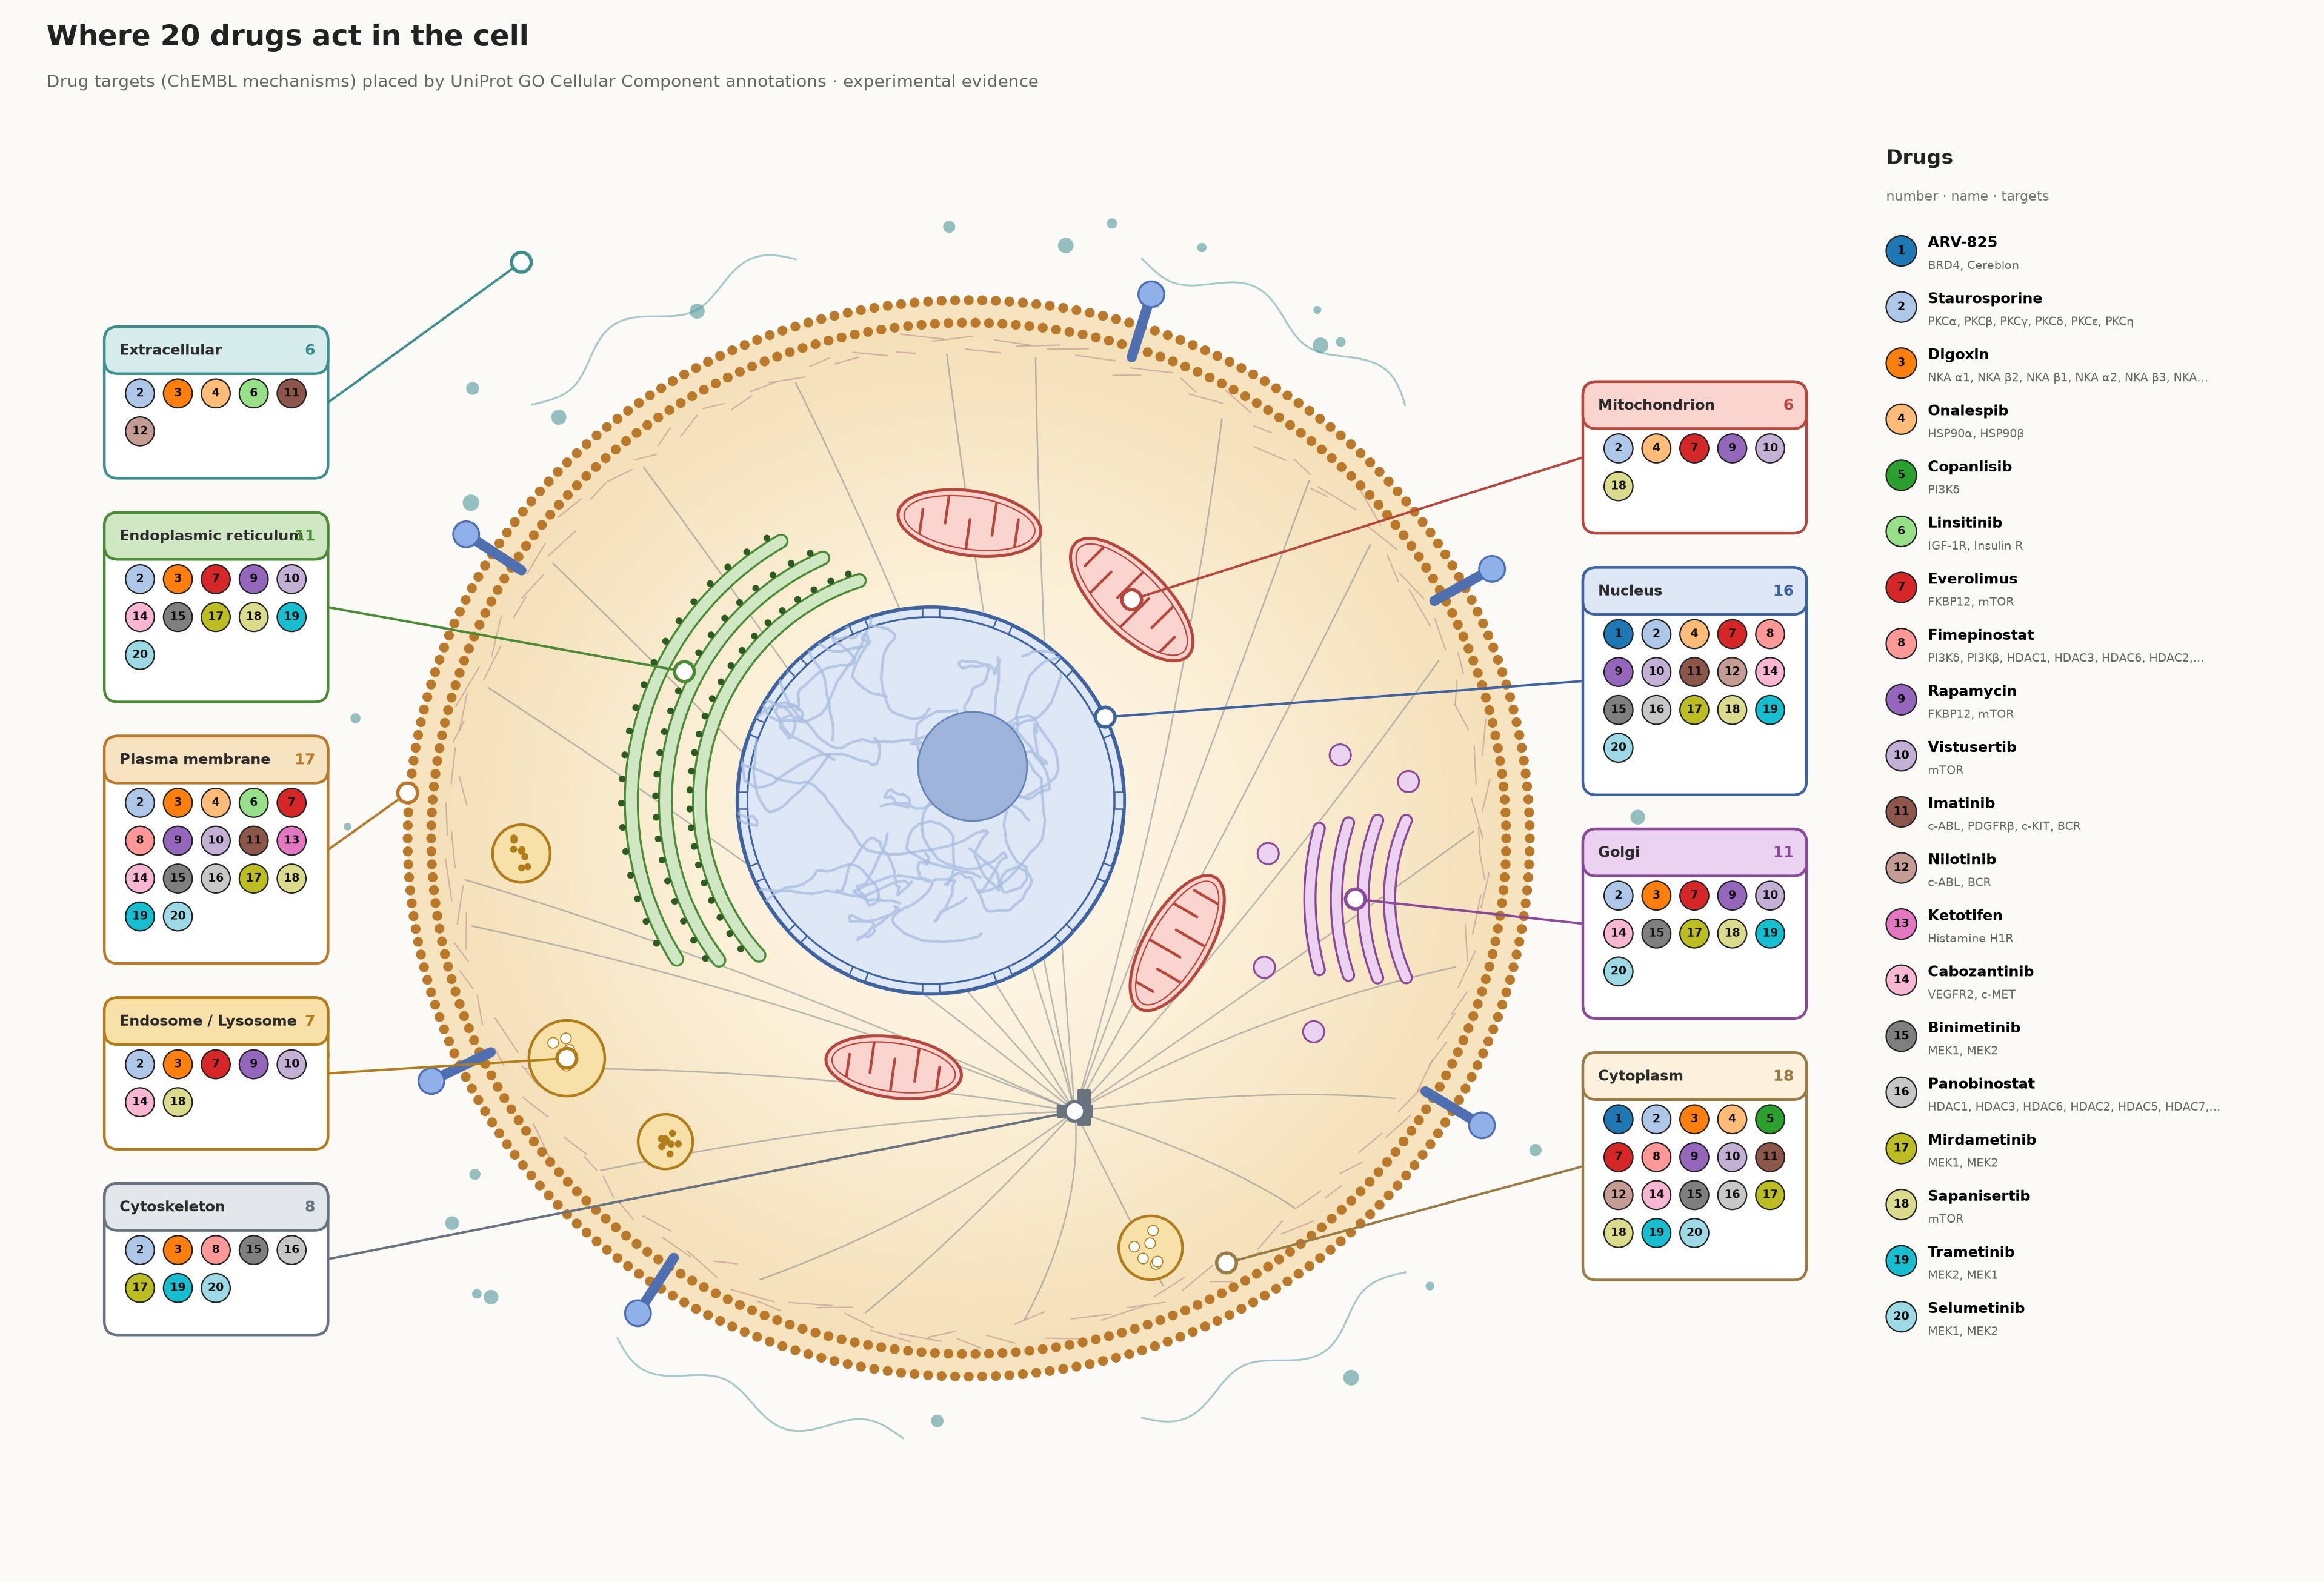

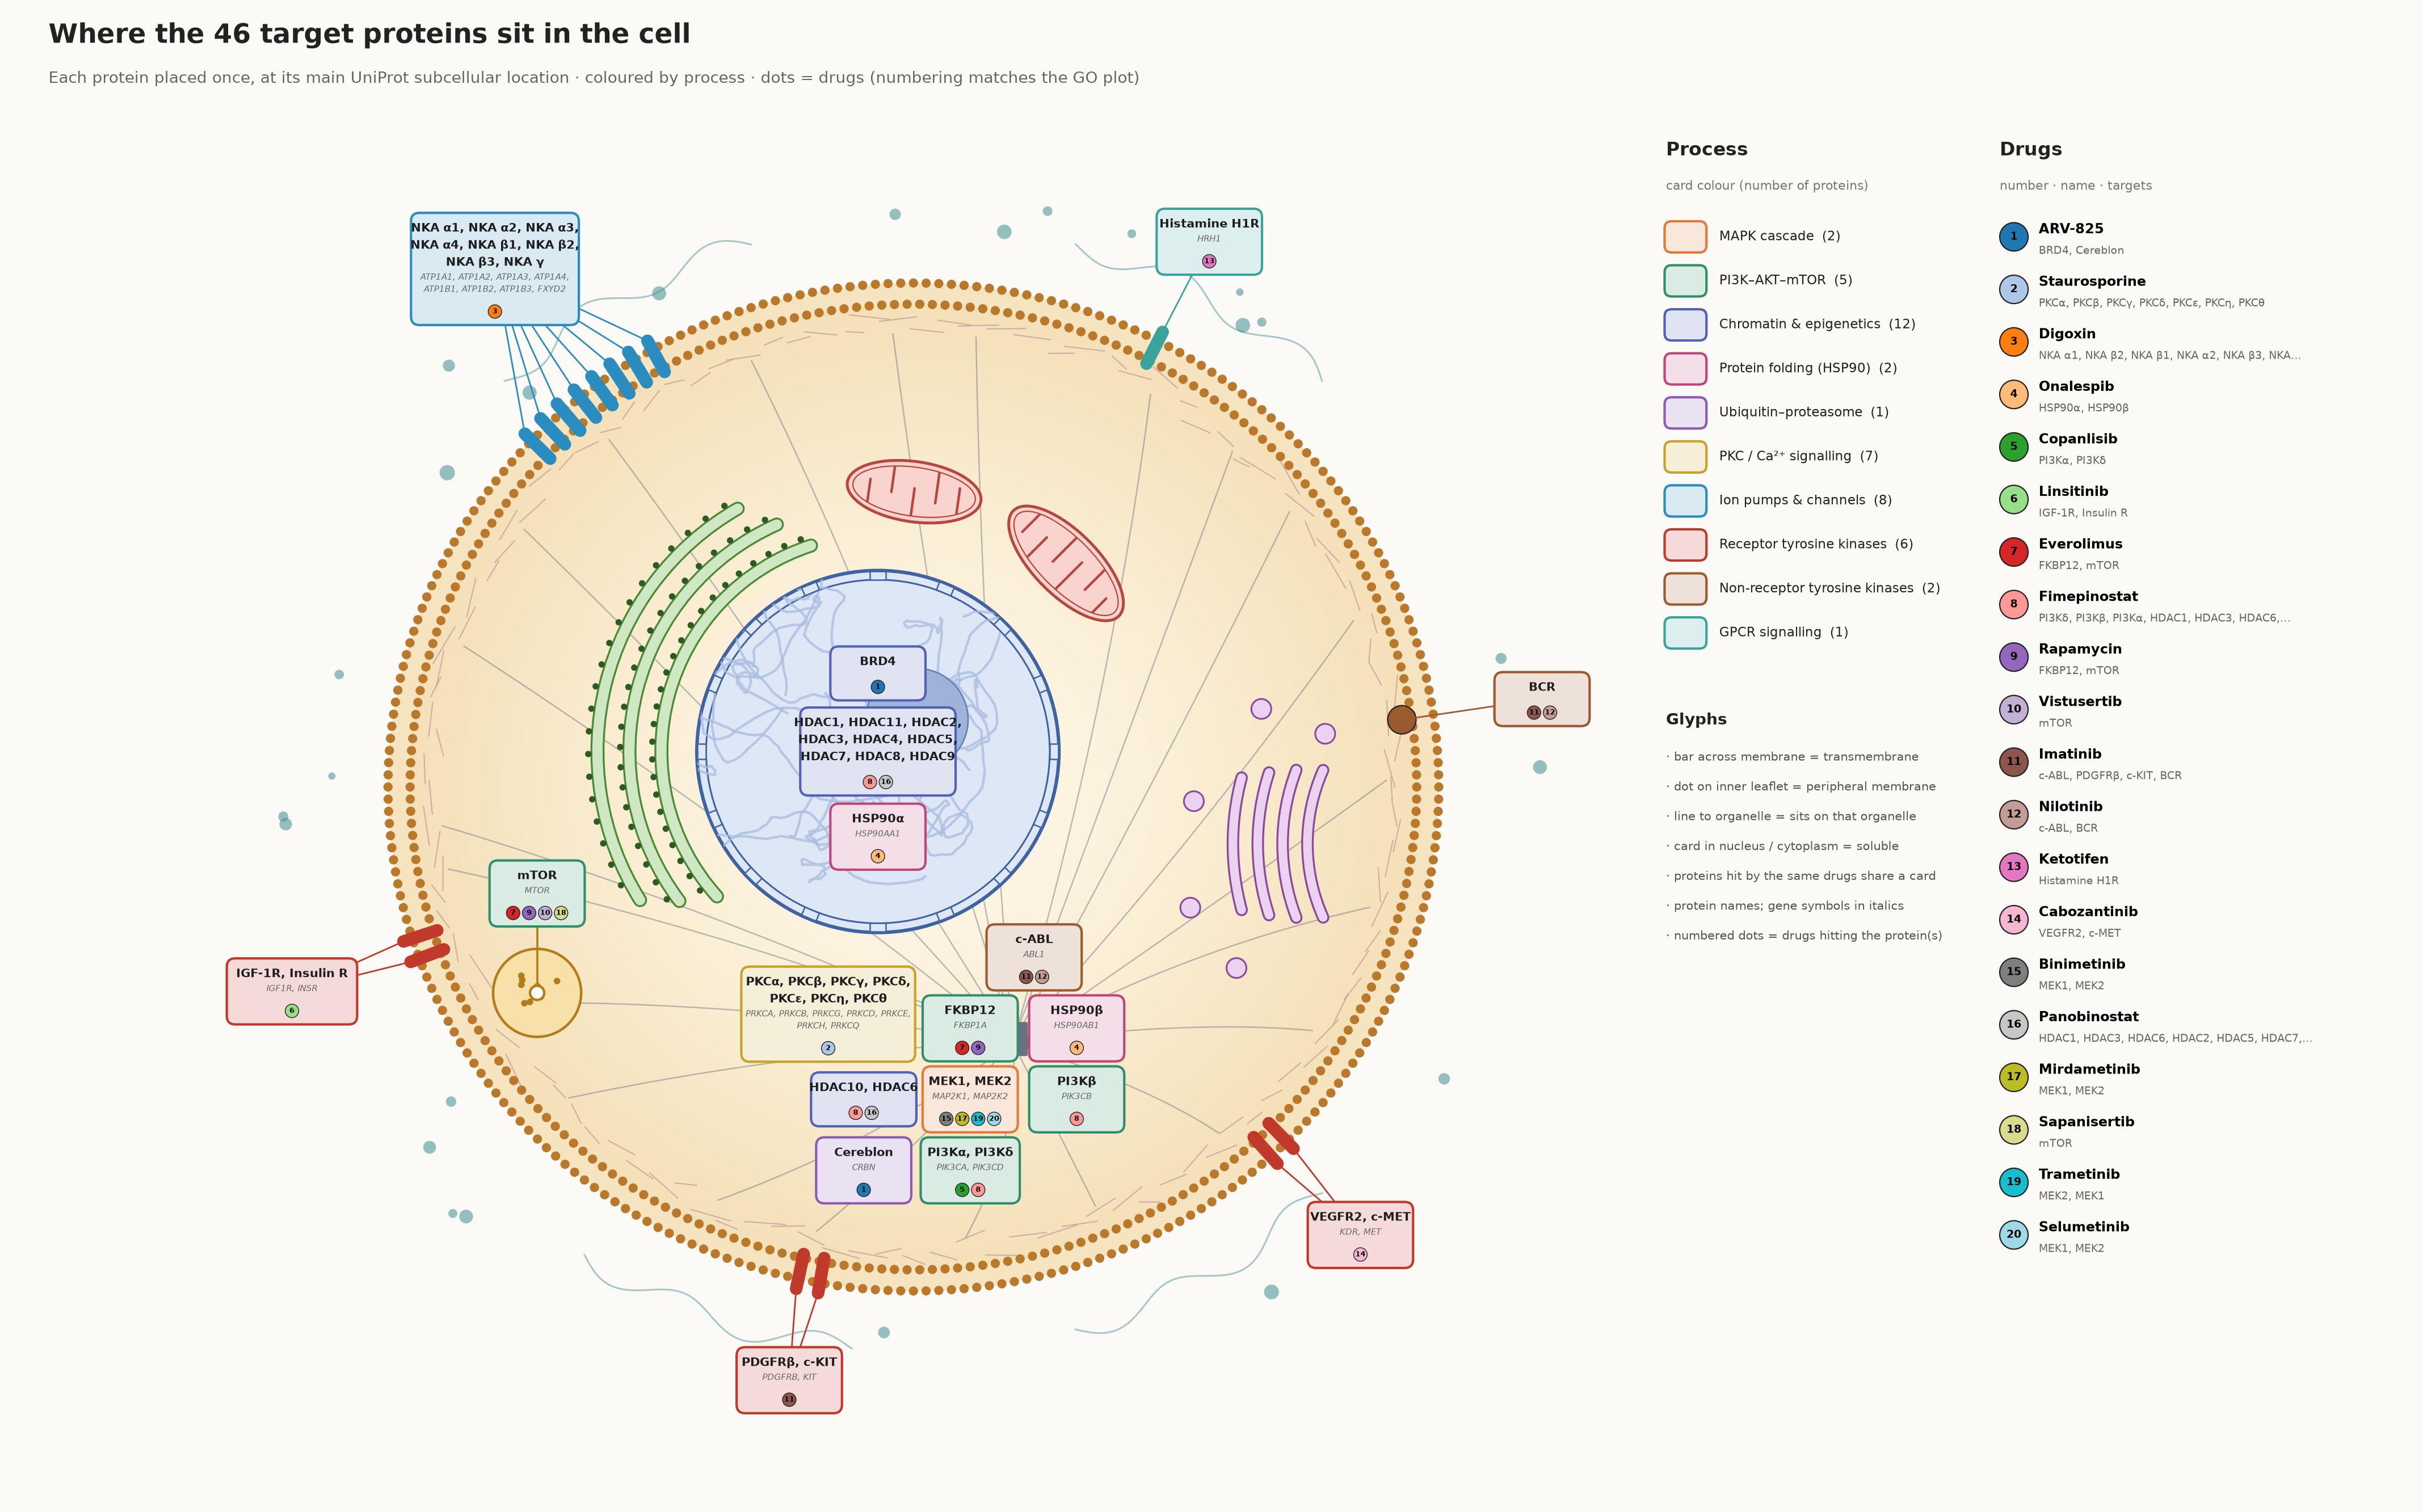

In [18]:
from IPython.display import Image, display

display(Image(f"{cell_structures_targets_image_out_file_path}", width=1100))
display(Image(f"{cell_protein_targets_image_out_file_path}", width=1100))